In [1]:
from pythonradex import radiative_transfer, helpers
from scipy import constants
import matplotlib.pyplot as plt
import numpy as np

In [2]:
datafilepath = "/Users/kyriakos.trakakis/Downloads/Radex/data/13co.dat"  # file downloaded from EMAA or LAMDA database
geometry = "static sphere"
line_profile_type = "Gaussian"
width_v = 1 * constants.kilo # Source FWHM
source = radiative_transfer.Source(
    datafilepath=datafilepath,
    geometry=geometry,
    line_profile_type=line_profile_type,
    width_v=width_v,
)

In [3]:
# N is the CO column density in m-2. Note that for spherical geometries, the input optical depth corresponds
# to the diameter of the sphere.
N = 1e15 / constants.centi**2
Tkin = 10  # kinetic temperature in [K]
# collider densities in m-3:
collider_densities = {
    "para-H2": 2e2 / constants.centi**3,
    "ortho-H2": 6e2 / constants.centi**3,
}
# external background: CMB at redshift 0. For no background, simply set ext_background=0.
# You can also provide your own function for the background. It should take an array
# of frequencies as input and return the radiation field at those frequencies in units
# of W/m2/Hz/sr
ext_background = helpers.generate_CMB_background(z=0)
# no dust in this example:
T_dust = 0
tau_dust = 0
source.update_parameters(
    N=N,
    Tkin=Tkin,
    collider_densities=collider_densities,
    ext_background=ext_background,
    T_dust=T_dust,
    tau_dust=tau_dust,
)

In [4]:
source.solve_radiative_transfer()

In [7]:
index_32 = 2  ## 0 for 1-0, 1 for 2-1, 2 for 3-2
print(
    f"optical depth at line center: {source.tau_nu0_individual_transitions[index_21]:.3g}"
)
print(f"Tex: {source.Tex[index_32]:.3g} K")
## If Tex < Tkin we are in non-LTE

optical depth at line center: 0.0607
Tex: 4.7 K


In [8]:
area = (1 * constants.au) ** 2
distance = 100 * constants.parsec
solid_angle = area / distance**2
# we can get the fluxes of several transitions by providing a list of indices,
# or of a single transition, as here:
transitions = index_21
flux_32 = source.frequency_integrated_emission(
    output_type="flux", solid_angle=solid_angle, transitions=transitions
)
print(f"flux of CO 3-2: {flux_32:.3g} W/m2")
intensity_32 = source.frequency_integrated_emission(
    output_type="intensity", transitions=transitions
)
print(f"intensity of CO 3-2: {intensity_32:.3g} W/m2/sr")

flux of CO 3-2: 2.07e-27 W/m2
intensity of CO 3-2: 8.81e-13 W/m2/sr


Text(0, 0.5, 'optical depth [-]')

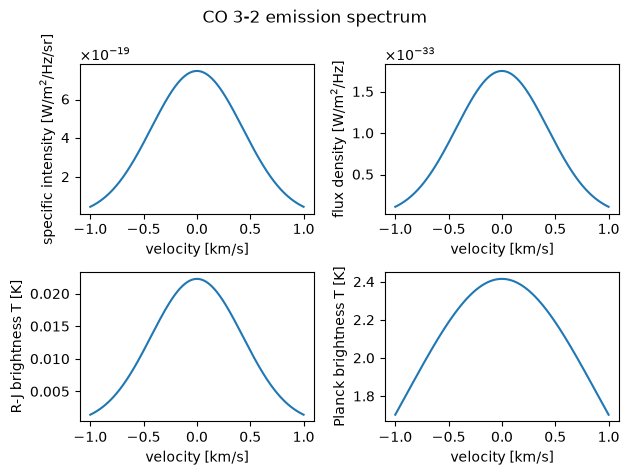

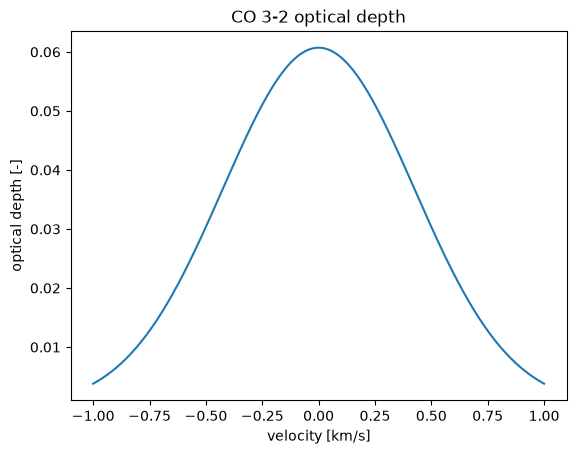

In [9]:
# define the grid of frequencies for which we want the emission spectrum
# and optical depth:
v = np.linspace(-width_v, width_v, 2000)
nu0_32 = source.emitting_molecule.nu0[index_21]  # rest frequency of CO based on what index_21 we gave (transition)
nu = nu0_32 * (1 - v / constants.c)
specific_intensity = source.spectrum(output_type="specific intensity", nu=nu)
flux_density = source.spectrum(
    output_type="flux density", solid_angle=solid_angle, nu=nu
)
RJ_brightness_temp = source.spectrum(output_type="Rayleigh-Jeans", nu=nu)
Planck_brightness_temp = source.spectrum(output_type="Planck", nu=nu)
tau = source.tau(nu=nu)

fig, axes = plt.subplots(ncols=2, nrows=2)
fig.suptitle("CO 3-2 emission spectrum")
axes[0, 0].plot(v / constants.kilo, specific_intensity)
axes[0, 0].set_ylabel(r"specific intensity [W/m$^2$/Hz/sr]")
axes[0, 1].plot(v / constants.kilo, flux_density)
axes[0, 1].set_ylabel(r"flux density [W/m$^2$/Hz]")
for ax in (axes[0, 0], axes[0, 1]):
    ax.yaxis.set_major_formatter(plt.ScalarFormatter(useMathText=True))
axes[1, 0].plot(v / constants.kilo, RJ_brightness_temp)
axes[1, 0].set_ylabel(r"R-J brightness T [K]")
axes[1, 1].plot(v / constants.kilo, Planck_brightness_temp)
axes[1, 1].set_ylabel(r"Planck brightness T [K]")
for ax in axes.ravel():
    ax.set_xlabel("velocity [km/s]")
fig.tight_layout()

_, ax = plt.subplots()
ax.set_title("CO 3-2 optical depth")
ax.plot(v / constants.kilo, tau)
ax.set_xlabel("velocity [km/s]")
ax.set_ylabel(r"optical depth [-]")

In [10]:
output_types = ("specific intensity", "flux density", "Rayleigh-Jeans", "Planck")
units = ("W/m2/Hz/sr", "W/m2/Hz", "K", "K")

for output_type, unit in zip(output_types, units):
    emission = source.emission_at_line_center(
        output_type=output_type,
        transitions=transitions,
        solid_angle=(solid_angle if output_type == "flux density" else None),
    )
    print(f"{output_type} at line center: {emission:.3g} {unit}")

specific intensity at line center: 7.47e-19 W/m2/Hz/sr
flux density at line center: 1.76e-33 W/m2/Hz
Rayleigh-Jeans at line center: 0.0223 K
Planck at line center: 2.41 K


In [11]:
source.print_results()



  up   low      nu0 [GHz]    T_ex [K]      poplow         popup         tau_nu0
   1    0     110.201354       5.75       0.420088       0.502428       0.358947
   2    1     220.398684       4.36       0.502428      0.0738547       0.433691
   3    2     330.587965       4.70      0.0738547     0.00353971      0.0607103
   4    3     440.765173       5.36     0.00353971    8.76876e-05     0.00281014
   5    4     550.926285       6.35    8.76876e-05    1.66665e-06     6.7804e-05
   6    5     661.067277       7.01    1.66665e-06    2.13465e-08     1.2688e-06
   7    6     771.184125       7.55    2.13465e-08    1.83289e-10    1.60569e-08
   8    7     881.272809       7.91    1.83289e-10    9.88654e-13    1.36502e-10
   9    8     991.329307       8.13    9.88654e-13    3.17619e-15    7.29663e-13
  10    9    1101.349597       8.31    3.17619e-15    6.08114e-18    2.32417e-15
  11   10    1211.329662       8.47    6.08114e-18    6.96682e-21     4.4109e-18
  12   11    1321.265481   

In [12]:
new_Tkin = 30
source.update_parameters(Tkin=new_Tkin)
source.solve_radiative_transfer()
print(f"Tex: {source.Tex[index_21]:.3g} K")
source.print_results()

Tex: 7.09 K


  up   low      nu0 [GHz]    T_ex [K]      poplow         popup         tau_nu0
   1    0     110.201354      13.35       0.265595       0.536124       0.123461
   2    1     220.398684       6.37       0.536124       0.169708       0.411144
   3    2     330.587965       7.09       0.169708      0.0253654       0.129028
   4    3     440.765173       8.67      0.0253654     0.00284337      0.0187428
   5    4     550.926285      11.16     0.00284337    0.000325362     0.00202426
   6    5     661.067277      13.21    0.000325362    3.48463e-05    0.000227715
   7    6     771.184125      15.10    3.48463e-05     3.4664e-06    2.41313e-05
   8    7     881.272809      16.65     3.4664e-06    3.09913e-07    2.38927e-06
   9    8     991.329307      17.73    3.09913e-07    2.36853e-08      2.137e-07
  10    9    1101.349597      18.78    2.36853e-08    1.56931e-09     1.6321e-08
  11   10    1211.329662      19.50    1.56931e-09    8.72185e-11    1.08166e-09
  12   11    13

In [13]:
LTE_collider_densities = {
    "para-H2": 1e6 / constants.centi**3,
    "ortho-H2": 3e6 / constants.centi**3,
}
source.update_parameters(collider_densities=LTE_collider_densities)
source.solve_radiative_transfer()
print(f"Tex of 3-2: {source.Tex[index_21]:.5g} K (Tkin = {new_Tkin} K)")

# LTE is recovered as Tex ~ Tkin

Tex of 3-2: 29.945 K (Tkin = 30 K)


In [14]:
# the fractional population of each level of the CO molecule
source.emitting_molecule.Boltzmann_level_population(T=new_Tkin)

array([8.55820922e-02, 2.15248674e-01, 2.52153322e-01, 2.08023743e-01,
       1.32138892e-01, 6.68988132e-02, 2.74590132e-02, 9.22664304e-03,
       2.55344718e-03, 5.84378230e-04, 1.10913477e-04, 1.74947417e-05,
       2.29696932e-06, 2.51344150e-07, 2.29447598e-08, 1.74886984e-09,
       1.11376017e-10, 5.92985533e-12, 2.64082680e-13, 9.84190182e-15,
       3.07072998e-16, 8.02402963e-18, 1.75664669e-19, 3.22300168e-21,
       4.95743011e-23, 6.39444054e-25, 6.91868917e-27, 6.28119687e-29,
       4.78605600e-31, 3.06159393e-33, 1.64463034e-35, 7.42088447e-38,
       2.81335938e-40, 8.96380768e-43, 2.40089764e-45, 5.40735967e-48,
       1.02434199e-50, 1.63256884e-53, 2.18970107e-56, 2.47232956e-59,
       2.35049349e-62])

In [15]:
nH2_grid = np.logspace(2, 6, 60)     # cm^-3
N13_grid = np.logspace(14.2, 16.2, 60)   # cm^-2

In [16]:
# CHIMPS transition: 13CO (3-2)
index_32 = 0

# Fixed parameters for first experiment
Tkin_grid = 10.0       # K
opr = 3             # ortho/para H2 ratio

# Arrays to store outputs
Tex32 = np.zeros((len(nH2_grid), len(N13_grid)))
tau32 = np.zeros_like(Tex32)
Tb32 = np.zeros_like(Tex32)

for i, nH2 in enumerate(nH2_grid):

    # Split total H2 density according to the chosen OPR
    n_para_cm3 = nH2 / (1.0 + opr)
    n_ortho_cm3 = nH2 * opr / (1.0 + opr)

    collider_densities = {
        "para-H2": n_para_cm3 / constants.centi**3,
        "ortho-H2": n_ortho_cm3 / constants.centi**3,
    }

    for j, N13 in enumerate(N13_grid):

        source.update_parameters(
            N=N13 / constants.centi**2,
            Tkin=Tkin_grid,
            collider_densities=collider_densities,
        )

        source.solve_radiative_transfer()

        Tex32[i, j] = source.Tex[index_32]
        tau32[i, j] = source.tau_nu0_individual_transitions[index_32]

        Tb32[i, j] = source.emission_at_line_center(
            output_type="Rayleigh-Jeans",
            transitions=index_32,
        )

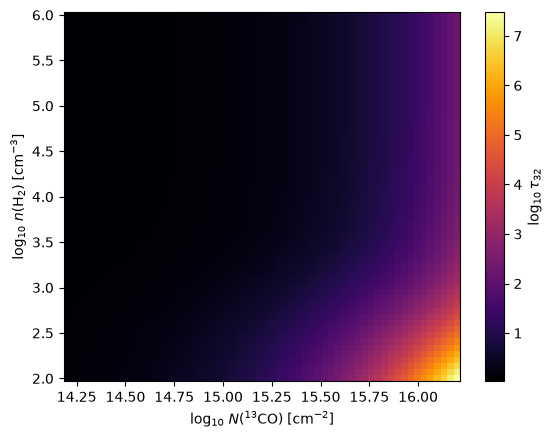

In [17]:
fig, ax = plt.subplots()

im = ax.pcolormesh(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    tau32,
    shading="auto",
    cmap = "inferno"
)

ax.set_xlabel(r"$\log_{10}\,N(^{13}\mathrm{CO})\;[\mathrm{cm}^{-2}]$")
ax.set_ylabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\log_{10}\tau_{32}$")

plt.show()

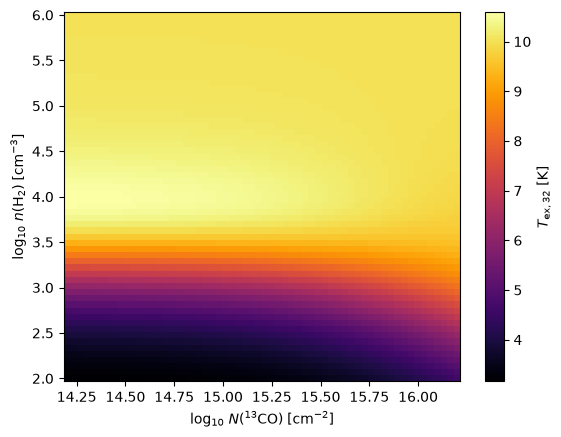

In [18]:
fig, ax = plt.subplots()

im = ax.pcolormesh(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    Tex32,
    shading="auto",
    cmap = "inferno"
)

ax.set_xlabel(r"$\log_{10}\,N(^{13}\mathrm{CO})\;[\mathrm{cm}^{-2}]$")
ax.set_ylabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$T_{\mathrm{ex},32}$ [K]")

plt.show()

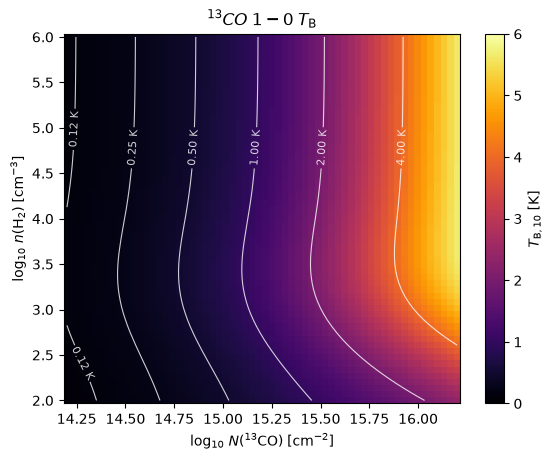

In [40]:
## Brightness temperature (emission at line centre)

index_32 = 0

# Fixed parameters for first experiment
Tkin_grid = 10.0       # K
opr = 3             # ortho/para H2 ratio

# Arrays to store outputs
Tex32 = np.zeros((len(nH2_grid), len(N13_grid)))
tau32 = np.zeros_like(Tex32)
Tb32 = np.zeros_like(Tex32)

for i, nH2 in enumerate(nH2_grid):

    # Split total H2 density according to the chosen OPR
    n_para_cm3 = nH2 / (1.0 + opr)
    n_ortho_cm3 = nH2 * opr / (1.0 + opr)

    collider_densities = {
        "para-H2": n_para_cm3 / constants.centi**3,
        "ortho-H2": n_ortho_cm3 / constants.centi**3,
    }

    for j, N13 in enumerate(N13_grid):

        source.update_parameters(
            N=N13 / constants.centi**2,
            Tkin=Tkin_grid,
            collider_densities=collider_densities,
        )

        source.solve_radiative_transfer()

        Tex32[i, j] = source.Tex[index_32]
        tau32[i, j] = source.tau_nu0_individual_transitions[index_32]

        Tb32[i, j] = source.emission_at_line_center(
            output_type="Rayleigh-Jeans",
            transitions=index_32,
        )

levels = [0.125, 0.25, 0.5, 1, 2, 4]

fig, ax = plt.subplots()

cs = ax.contour(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    Tb32,
    levels=levels,
    colors='white',
    linewidths=0.8,
    alpha=0.8
)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.2f K',
          colors='white', inline_spacing=3)

im = ax.pcolormesh(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    Tb32,
    shading="auto",
    cmap = "inferno",
    vmin = 0,
    vmax = 6
)

ax.set_xlabel(r"$\log_{10}\,N(^{13}\mathrm{CO})\;[\mathrm{cm}^{-2}]$")
ax.set_ylabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$T_{\mathrm{B},10}$ [K]")
plt.title(r'$^{13}CO\; 1-0\; T_{\mathrm{B}}$') 

#plt.show()
#plt.savefig('Tkin_10K_FGN.png')

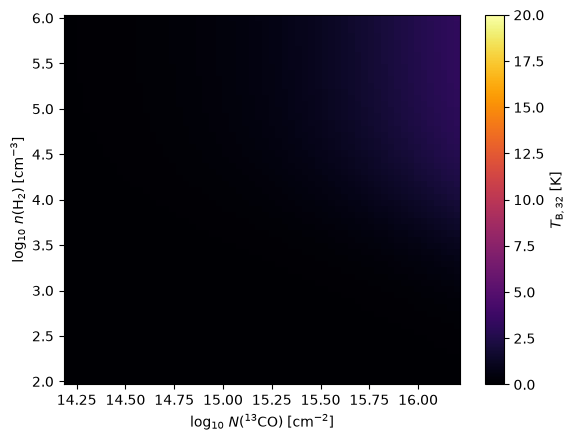

In [20]:
# CHIMPS transition: 13CO (3-2)
index_32 = 2

# Fixed parameters for first experiment
Tkin_grid = 10.0       # K
opr = 1e-2             # ortho/para H2 ratio

# Arrays to store outputs
Tex32 = np.zeros((len(nH2_grid), len(N13_grid)))
tau32 = np.zeros_like(Tex32)
Tb32 = np.zeros_like(Tex32)

for i, nH2 in enumerate(nH2_grid):

    # Split total H2 density according to the chosen OPR
    n_para_cm3 = nH2 / (1.0 + opr)
    n_ortho_cm3 = nH2 * opr / (1.0 + opr)

    collider_densities = {
        "para-H2": n_para_cm3 / constants.centi**3,
        "ortho-H2": n_ortho_cm3 / constants.centi**3,
    }

    for j, N13 in enumerate(N13_grid):

        source.update_parameters(
            N=N13 / constants.centi**2,
            Tkin=Tkin_grid,
            collider_densities=collider_densities,
        )

        source.solve_radiative_transfer()

        Tex32[i, j] = source.Tex[index_32]
        tau32[i, j] = source.tau_nu0_individual_transitions[index_32]

        Tb32[i, j] = source.emission_at_line_center(
            output_type="Rayleigh-Jeans",
            transitions=index_32,
        )

fig, ax = plt.subplots()

im = ax.pcolormesh(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    Tb32,
    shading="auto",
    cmap = "inferno",
    vmin = 0,
    vmax = 20
)

ax.set_xlabel(r"$\log_{10}\,N(^{13}\mathrm{CO})\;[\mathrm{cm}^{-2}]$")
ax.set_ylabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$T_{\mathrm{B},32}$ [K]")

#plt.show()
#plt.savefig('Tkin_20.png')

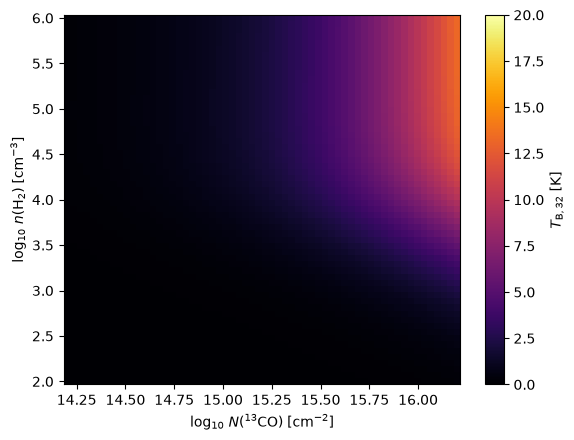

In [21]:
# CHIMPS transition: 13CO (3-2)
index_32 = 2

# Fixed parameters for first experiment
Tkin_grid = 30.0       # K
opr = 1e-2             # ortho/para H2 ratio

# Arrays to store outputs
Tex32 = np.zeros((len(nH2_grid), len(N13_grid)))
tau32 = np.zeros_like(Tex32)
Tb32 = np.zeros_like(Tex32)

for i, nH2 in enumerate(nH2_grid):

    # Split total H2 density according to the chosen OPR
    n_para_cm3 = nH2 / (1.0 + opr)
    n_ortho_cm3 = nH2 * opr / (1.0 + opr)

    collider_densities = {
        "para-H2": n_para_cm3 / constants.centi**3,
        "ortho-H2": n_ortho_cm3 / constants.centi**3,
    }

    for j, N13 in enumerate(N13_grid):

        source.update_parameters(
            N=N13 / constants.centi**2,
            Tkin=Tkin_grid,
            collider_densities=collider_densities,
        )

        source.solve_radiative_transfer()

        Tex32[i, j] = source.Tex[index_32]
        tau32[i, j] = source.tau_nu0_individual_transitions[index_32]

        Tb32[i, j] = source.emission_at_line_center(
            output_type="Rayleigh-Jeans",
            transitions=index_32,
        )

fig, ax = plt.subplots()

im = ax.pcolormesh(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    Tb32,
    shading="auto",
    cmap = "inferno",
    vmin = 0,
    vmax = 20
)

ax.set_xlabel(r"$\log_{10}\,N(^{13}\mathrm{CO})\;[\mathrm{cm}^{-2}]$")
ax.set_ylabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$T_{\mathrm{B},32}$ [K]")

#plt.show()
#plt.savefig('Tkin_30.png')

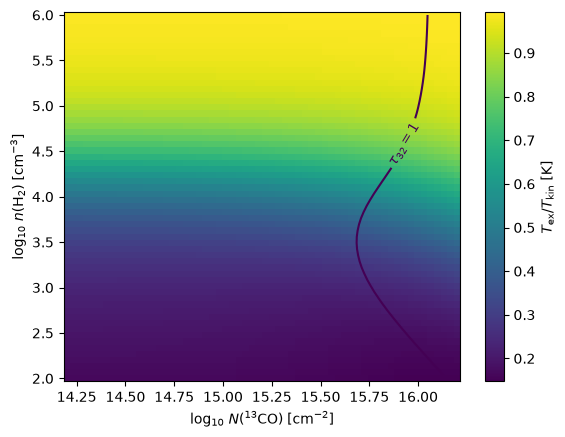

In [22]:
Tex_fraction = Tex32 / Tkin_grid
## As Tex_fraction -> 1 gas becomes thermalised and we approach LTE

fig, ax = plt.subplots()

im = ax.pcolormesh(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    Tex_fraction,
    shading="auto",
)

cs = ax.contour(
    np.log10(N13_grid),
    np.log10(nH2_grid),
    tau32,
    levels=[1.0],
)

ax.clabel(cs, fmt={1.0: r"$\tau_{32}=1$"})

ax.set_xlabel(r"$\log_{10}\,N(^{13}\mathrm{CO})\;[\mathrm{cm}^{-2}]$")
ax.set_ylabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")

fig.colorbar(im, ax=ax, label=r"$T_{\mathrm{ex}}/ T_{\mathrm{kin}}$ [K]")

plt.show()

## Increasing column density and volumn density simultaneously

In [298]:
index_32 = 0

Tkin = 10.0
opr = 1e-2

n_steps = 40

nH2_path = np.logspace(2, 5, n_steps)     # cm^-3
N13_path = np.logspace(14, 16, n_steps)   # cm^-2

Tex_path = np.zeros(n_steps)
tau_path = np.zeros(n_steps)
Tb_path = np.zeros(n_steps)

for i, (nH2, N13) in enumerate(zip(nH2_path, N13_path)):

    # Split total H2 density into para and ortho components
    n_para_cm3 = nH2 / (1.0 + opr)
    n_ortho_cm3 = opr * n_para_cm3

    collider_densities = {
        "para-H2": n_para_cm3 * 1e6,   # cm^-3 -> m^-3
        "ortho-H2": n_ortho_cm3 * 1e6,
    }

    source.update_parameters(
        N=N13 * 1e4,                   # cm^-2 -> m^-2
        Tkin=Tkin,
        collider_densities=collider_densities,
    )

    source.solve_radiative_transfer()

    Tex_path[i] = source.Tex[index_32]
    tau_path[i] = source.tau_nu0_individual_transitions[index_32]

    Tb_path[i] = source.emission_at_line_center(
        output_type="Rayleigh-Jeans",
        transitions=index_32,
    )

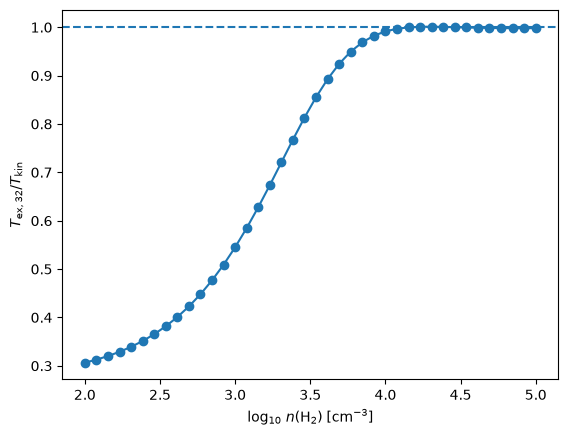

In [299]:
fig, ax = plt.subplots()

ax.plot(
    np.log10(nH2_path),
    Tex_path / Tkin,
    marker="o"
)

ax.set_xlabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")
ax.set_ylabel(r"$T_{\rm ex,32}/T_{\rm kin}$")

ax.axhline(1.0, linestyle="--")

plt.show()

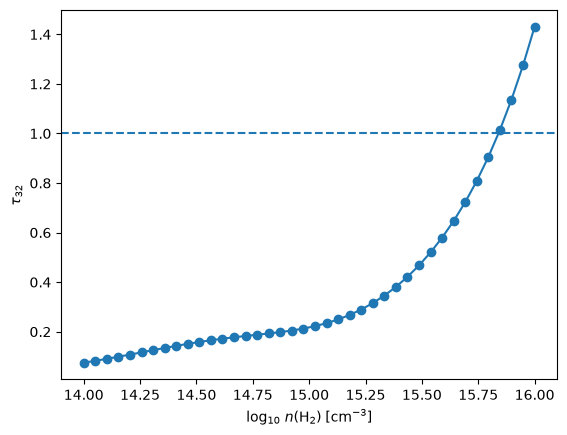

In [300]:
fig, ax = plt.subplots()

ax.plot(
    np.log10(N13_path),
    tau_path,
    marker="o"
)

ax.axhline(1.0, linestyle="--")

ax.set_xlabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")
ax.set_ylabel(r"$\tau_{32}$")
#plt.ylim([0,5])

plt.show()

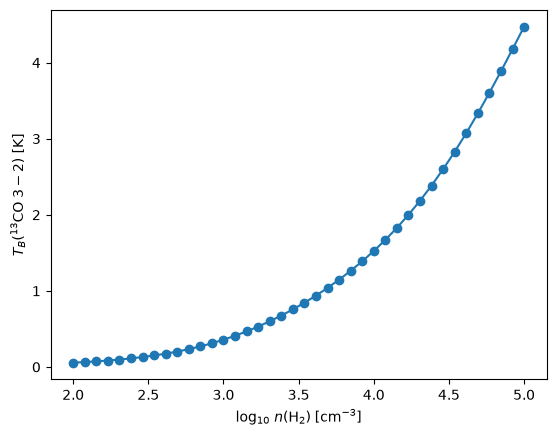

In [301]:
fig, ax = plt.subplots()

ax.plot(
    np.log10(nH2_path),
    Tb_path,
    marker="o"
)

ax.set_xlabel(r"$\log_{10}\,n(\mathrm{H}_2)\;[\mathrm{cm}^{-3}]$")
ax.set_ylabel(r"$T_B(^{13}\mathrm{CO}\;3-2)$ [K]")

plt.show()

## Simple spherical cloud with increasing density, and column calculated per line of sight

In [302]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Simple spherical cloud model, VERY DENSE!!
# -----------------------------

R = 5.0          # cloud radius [pc]
r0 = 0.5         # flattening radius [pc]
n0 = 1e5         # central H2 density [cm^-3]
n_bg = 1e2       # background/envelope density [cm^-3]
p = 2.0          # density-profile exponent

X13 = 1.5e-6     # 13CO/H2 abundance

pc_to_cm = 3.085677581e18


def nH2_profile(r):
    """
    H2 volume density [cm^-3]
    """
    return n_bg + n0 / (1.0 + (r / r0)**2)**(p / 2.0)

In [303]:
## Slightly more realistic

R = 2.0          # pc
r0 = 0.2         # pc
n0 = 3e3         # cm^-3
n_bg = 50        # cm^-3
p = 2.0

X13 = 1.5e-6

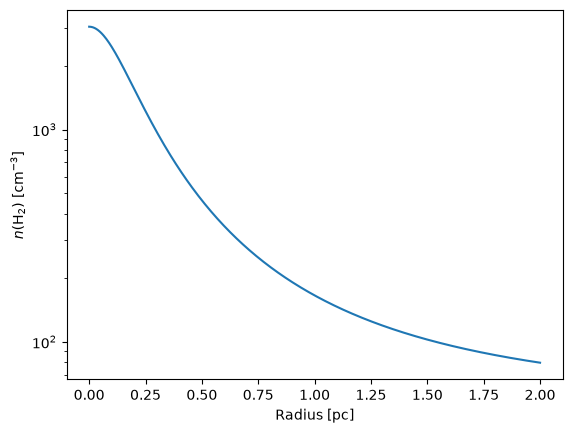

In [304]:
## Show the cloud
r = np.linspace(0, R, 500)

fig, ax = plt.subplots()

ax.plot(r, nH2_profile(r))

ax.set_yscale("log")
ax.set_xlabel("Radius [pc]")
ax.set_ylabel(r"$n(\mathrm{H}_2)$ [cm$^{-3}$]")

plt.show()

In [305]:
## Calculate column at each line of sight
def line_of_sight_properties(b, nz=2000):

    zmax = np.sqrt(R**2 - b**2)

    z = np.linspace(0, zmax, nz)

    r = np.sqrt(b**2 + z**2)

    n = nH2_profile(r)

    # integral n dz
    int_n = 2.0 * np.trapezoid(n, z)

    # H2 column: cm^-3 * pc -> cm^-2
    NH2 = int_n * pc_to_cm

    # 13CO column
    N13 = X13 * NH2

    # Characteristic density for our one-zone RADEX approximation
    #
    # This is a column-weighted density:
    #
    # <n> = integral(n^2 dz) / integral(n dz)
    #
    int_n2 = 2.0 * np.trapezoid(n**2, z)

    n_eff = int_n2 / int_n

    return NH2, N13, n_eff

## We need one uniform density for pythonradex, so we take the weighted density as a representative.

In [306]:
## Generate edge-to-centre sightlines
b_path = np.linspace(0.99 * R, 0.0, 50)

NH2_path = np.zeros(len(b_path))
N13_path = np.zeros(len(b_path))
nH2_eff_path = np.zeros(len(b_path))

for i, b in enumerate(b_path):

    NH2_path[i], N13_path[i], nH2_eff_path[i] = \
        line_of_sight_properties(b)

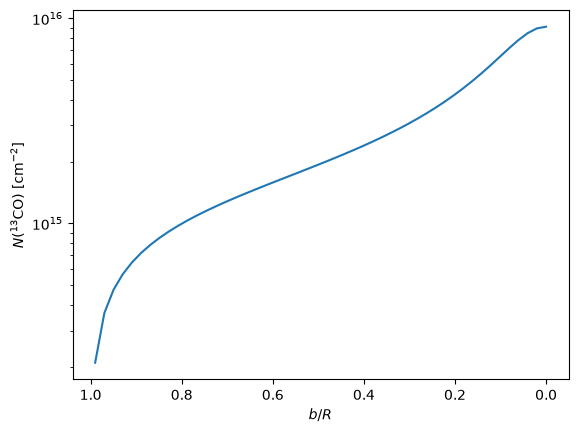

In [307]:
fig, ax = plt.subplots()

ax.plot(b_path / R, N13_path)

ax.set_yscale("log")
ax.invert_xaxis()

ax.set_xlabel(r"$b/R$")
ax.set_ylabel(
    r"$N(^{13}\mathrm{CO})$ [cm$^{-2}$]"
)

plt.show()

## Remember, b is just the iterative parameter that moves out from the edge to the centre, it has no other meaning!

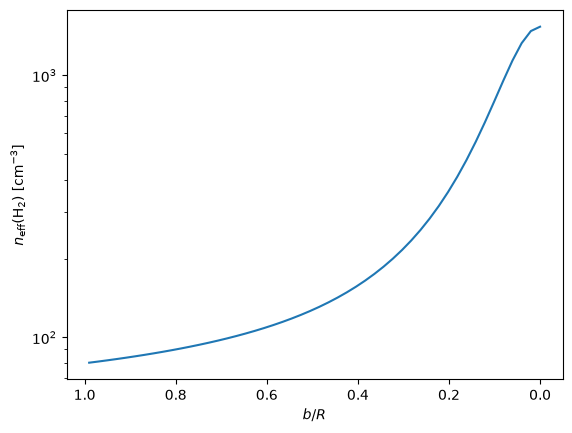

In [308]:
fig, ax = plt.subplots()

ax.plot(b_path / R, nH2_eff_path)
#ax.plot(b_path / R, N13_path)

ax.set_yscale("log")
ax.invert_xaxis()

ax.set_xlabel(r"$b/R$")
ax.set_ylabel(
    r"$n_{\rm eff}(\mathrm{H}_2)$ [cm$^{-3}$]"
)

plt.show()

In [309]:
index_32 = 0

Tkin = 10.0
opr = 1e-2

Tex_path = np.zeros(len(b_path))
tau_path = np.zeros(len(b_path))
Tb_path = np.zeros(len(b_path))

for i, (nH2, N13) in enumerate(zip(nH2_eff_path, N13_path)):

    # H2 ortho / para split
    n_para_cm3 = nH2 / (1.0 + opr)
    n_ortho_cm3 = opr * n_para_cm3

    collider_densities = {
        "para-H2": n_para_cm3 * 1e6,
        "ortho-H2": n_ortho_cm3 * 1e6,
    }

    source.update_parameters(
        N=N13 * 1e4,       # cm^-2 -> m^-2
        Tkin=Tkin,
        collider_densities=collider_densities,
    )

    source.solve_radiative_transfer()

    Tex_path[i] = source.Tex[index_32]

    tau_path[i] = (
        source.tau_nu0_individual_transitions[index_32]
    )

    Tb_path[i] = source.emission_at_line_center(
        output_type="Rayleigh-Jeans",
        transitions=index_32,
    )

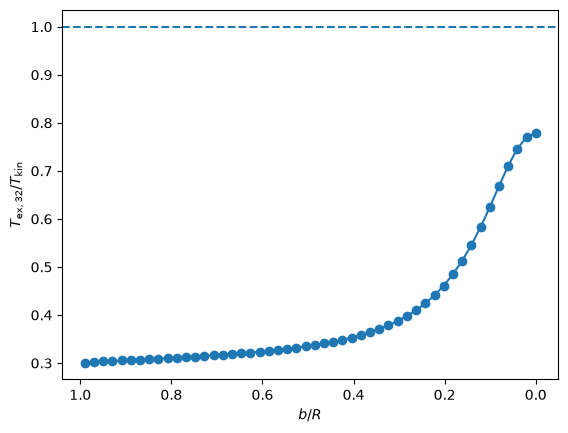

In [310]:
fig, ax = plt.subplots()

ax.plot(
    b_path / R,
    Tex_path / Tkin,
    marker="o"
)

ax.invert_xaxis()

ax.axhline(1.0, linestyle="--")

ax.set_xlabel(r"$b/R$")
ax.set_ylabel(
    r"$T_{\rm ex,32}/T_{\rm kin}$"
)

plt.show()

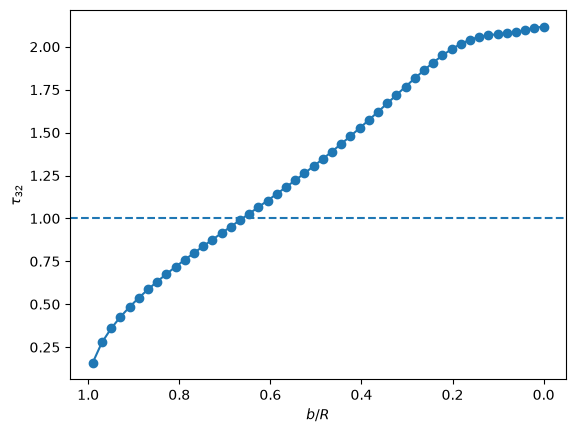

In [311]:
fig, ax = plt.subplots()

ax.plot(
    b_path / R,
    tau_path,
    marker="o"
)

ax.invert_xaxis()

ax.axhline(1.0, linestyle="--")

ax.set_xlabel(r"$b/R$")
ax.set_ylabel(r"$\tau_{32}$")

plt.show()

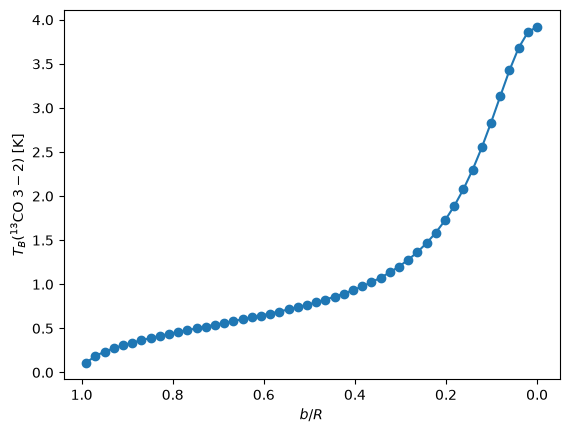

In [312]:
fig, ax = plt.subplots()

ax.plot(
    b_path / R,
    Tb_path,
    marker="o"
)

ax.invert_xaxis()

ax.set_xlabel(r"$b/R$")
ax.set_ylabel(
    r"$T_B(^{13}\mathrm{CO}\;3-2)$ [K]"
)

plt.show()

In [168]:
np.log10(N13_path).min()

np.float64(14.320557507895568)

In [313]:
print("N13 =", np.log10(N13_path[-1]))
print("n_eff =", np.log10(nH2_eff_path[-1]))
print("Tex32 =", Tex_path[-1])
print("tau32 =", tau_path[-1])
print("Tb32 =", Tb_path[-1])

N13 = 15.95888241534543
n_eff = 3.1855272345913384
Tex32 = 7.785240145256716
tau32 = 2.116869112218103
Tb32 = 3.9217723806283424


## Trying to recreate realistic clouds

In [314]:
from pythonradex import radiative_transfer, helpers
from scipy import constants
import numpy as np
import pandas as pd

index_32 = 0

def make_source(fwhm_kms):
    return radiative_transfer.Source(
        datafilepath=datafilepath,
        geometry="static sphere",
        line_profile_type="Gaussian",
        width_v=fwhm_kms * constants.kilo,
    )

In [315]:
N13_grid = np.logspace(14, 16, 25)      # cm^-2
nH2_grid = np.logspace(2, 6, 25)        # cm^-3

Tkin_grid = [8, 10, 15, 20, 30]         # K
fwhm_grid = [0.5, 1.0, 2.0, 3.0, 5.0]  # km/s

opr = 1e-2

In [316]:
results = []

ext_background = helpers.generate_CMB_background(z=0)

for fwhm in fwhm_grid:

    # Width is fixed inside each Source
    source = make_source(fwhm)

    for Tkin in Tkin_grid:

        for nH2 in nH2_grid:

            n_para = nH2 / (1.0 + opr)
            n_ortho = opr * n_para

            collider_densities = {
                "para-H2": n_para * 1e6,    # cm^-3 -> m^-3
                "ortho-H2": n_ortho * 1e6,
            }

            for N13 in N13_grid:

                source.update_parameters(
                    N=N13 * 1e4,            # cm^-2 -> m^-2
                    Tkin=Tkin,
                    collider_densities=collider_densities,
                    ext_background=ext_background,
                    T_dust=0,
                    tau_dust=0,
                )

                source.solve_radiative_transfer()

                Tex32 = source.Tex[index_32]
                tau32 = source.tau_nu0_individual_transitions[index_32]

                Tb32 = source.emission_at_line_center(
                    output_type="Rayleigh-Jeans",
                    transitions=index_32,
                )

                results.append({
                    "N13": N13,
                    "nH2": nH2,
                    "Tkin": Tkin,
                    "fwhm": fwhm,
                    "Tex32": Tex32,
                    "tau32": tau32,
                    "Tb32": Tb32,
                })

In [317]:
df = pd.DataFrame(results)
df.head()

,N13,nH2,Tkin,fwhm,Tex32,tau32,Tb32
0,1.000000e+14,100.0,8,0.5,2.987888,0.153591,0.10501995857763317
1,1.211528e+14,100.0,8,0.5,2.990822,0.185898,0.1258833115898064
2,1.467799e+14,100.0,8,0.5,2.994390,0.224953,0.1505681669936697
3,1.778279e+14,100.0,8,0.5,2.998734,0.272143,0.1796355943721248
4,2.154435e+14,100.0,8,0.5,3.004026,0.329129,0.2136704819569479


In [318]:
tau_match = df[
    (df["tau32"] >= 4)
]
tau_match[
    ["N13", "nH2", "Tkin", "fwhm", "Tex32", "tau32", "Tb32"]
]

,N13,nH2,Tkin,fwhm,Tex32,tau32,Tb32
18,3.162278e+15,100.000000,8,0.5,3.438827,4.198635,1.2956060317029596
19,3.831187e+15,100.000000,8,0.5,3.529590,4.945110,1.4029021891322335
20,4.641589e+15,100.000000,8,0.5,3.633376,5.803155,1.5153462014538233
21,5.623413e+15,100.000000,8,0.5,3.750517,6.785722,1.634408925579765
22,6.812921e+15,100.000000,8,0.5,3.881092,7.907438,1.76146488640997
...,...,...,...,...,...,...,...
4398,8.254042e+15,100.000000,15,1.0,4.218695,4.326670,1.9030154154839862
4399,1.000000e+16,100.000000,15,1.0,4.395965,4.989908,2.0945786146503194
4424,1.000000e+16,146.779927,15,1.0,4.888087,4.374488,2.447281842338322
5024,1.000000e+16,100.000000,20,1.0,4.719956,4.563823,2.327856068463328


In [319]:
matches = df[
    (df["tau32"] >= 0.2) &
    (df["tau32"] <= 1.5) &
    (df["Tb32"] >= 1.0) &
    (df["Tb32"] <= 5.0)
]
matches.sort_values("Tb32")

,N13,nH2,Tkin,fwhm,Tex32,tau32,Tb32
3265,1.778279e+15,681.292069,8,1.0,4.480195,0.866578,1.0000183616669103
12747,6.812921e+15,3162.277660,8,5.0,6.662310,0.397274,1.0004775249928892
235,6.812921e+14,3162.277660,8,0.5,6.662310,0.397274,1.0004775249928977
3865,1.778279e+15,464.158883,10,1.0,4.491659,0.863056,1.0014466602403542
7092,2.610157e+15,2154.434690,10,2.0,7.467810,0.330323,1.0018676424217787
...,...,...,...,...,...,...,...
1871,5.623413e+15,1000000.000000,15,0.5,15.005167,0.790886,4.99489110241212
5798,8.254042e+15,1000.000000,30,1.0,14.846769,0.804835,4.996302368615207
4574,1.000000e+16,1467.799268,15,1.0,10.703655,1.486703,4.998202466826978
4724,1.000000e+16,14677.992676,15,1.0,15.114131,0.782740,4.999471258205183


In [320]:
N_target = 1e16
T_target = 10

subset = df[
    np.isclose(np.log10(df["N13"]), np.log10(N_target), atol=0.05) &
    (df["Tkin"] == T_target)
]

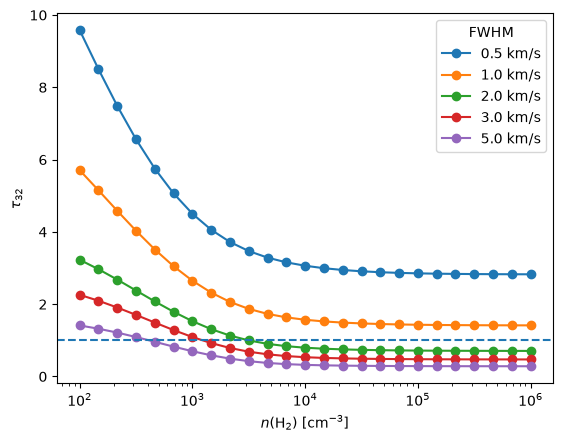

In [321]:
fig, ax = plt.subplots()

for fwhm in fwhm_grid:

    s = subset[subset["fwhm"] == fwhm]

    ax.plot(
        s["nH2"],
        s["tau32"],
        marker="o",
        label=f"{fwhm} km/s"
    )

ax.set_xscale("log")
#ax.set_yscale("log")

ax.set_xlabel(r"$n(\mathrm{H}_2)$ [cm$^{-3}$]")
ax.set_ylabel(r"$\tau_{32}$")

ax.axhline(1.0, linestyle="--")
ax.legend(title="FWHM")

plt.show()

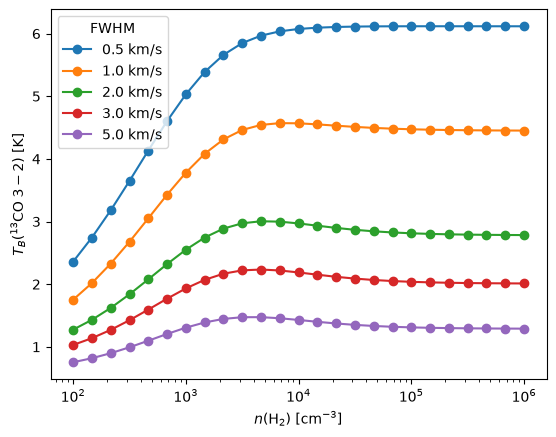

In [322]:
fig, ax = plt.subplots()

for fwhm in fwhm_grid:

    s = subset[subset["fwhm"] == fwhm]

    ax.plot(
        s["nH2"],
        s["Tb32"],
        marker="o",
        label=f"{fwhm} km/s"
    )

ax.set_xscale("log")

ax.set_xlabel(r"$n(\mathrm{H}_2)$ [cm$^{-3}$]")
ax.set_ylabel(r"$T_B(^{13}\mathrm{CO}\;3-2)$ [K]")

ax.legend(title="FWHM")

plt.show()